<a href="https://colab.research.google.com/github/lamaljalal/NLP/blob/main/Lab11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
# Upload Lab_11_QnA_Dataset.csv to Colab when prompted.
from pathlib import Path
from google.colab import files

candidates = [Path('/content/Lab_11_QnA_Dataset.csv'), Path('Lab_11_QnA_Dataset.csv'), Path('/content/Lab_11_QnA_Dataset_Download.csv')]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    print('Please upload Lab_11_QnA_Dataset.csv')
    uploaded = files.upload()
    dataset_path = Path(next((name for name in uploaded if name.endswith('.csv')), ''))
    if not dataset_path.is_file():
        raise FileNotFoundError('Please upload the supplied Lab_11_QnA_Dataset.csv')

df = pd.read_csv(dataset_path)
assert {'question','answer_id','answer'}.issubset(df.columns)
df = df.dropna(subset=['question','answer_id','answer']).reset_index(drop=True)
print('Number of questions:', len(df))
print('Number of answer groups:', df['answer_id'].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
import re
from collections import Counter

# Clean punctuation, lowercase, tokenize and pad using PyTorch-compatible code.
def tokenize(text):
    return re.findall(r"[a-z0-9']+", str(text).lower())

df['question'] = df['question'].astype(str).str.lower()
token_lists = [tokenize(q) for q in df['question']]
vocab = {'<PAD>': 0, '<UNK>': 1}
for words in token_lists:
    for word in words:
        if word not in vocab:
            vocab[word] = len(vocab)
max_len = max(map(len, token_lists))
X = torch.tensor([[vocab[w] for w in words] + [0] * (max_len - len(words)) for words in token_lists], dtype=torch.long)
classes = sorted(df['answer_id'].unique())
label_to_idx = {label: i for i,label in enumerate(classes)}
y = torch.tensor([label_to_idx[label] for label in df['answer_id']], dtype=torch.long)
answer_lookup = df.drop_duplicates('answer_id').set_index('answer_id')['answer'].to_dict()
print('Vocabulary size:', len(vocab), 'Max length:', max_len, 'Input shape:', tuple(X.shape))

Vocabulary size: 228 Max length: 11 Input shape: (168, 11)


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(vocab), 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, len(classes))

    def forward(self, x):
        hidden, _ = self.rnn(self.emb(x))
        scores = self.att(hidden).squeeze(-1)
        scores = scores.masked_fill(x.eq(0), -1e9)  # ignore padding
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

Epoch  20/100 | Loss: 0.9532 | Train accuracy: 76.2%
Epoch  40/100 | Loss: 0.1231 | Train accuracy: 97.0%
Epoch  60/100 | Loss: 0.0202 | Train accuracy: 100.0%
Epoch  80/100 | Loss: 0.0068 | Train accuracy: 100.0%
Epoch 100/100 | Loss: 0.0040 | Train accuracy: 100.0%
Training finished! Final training accuracy: 100.0%


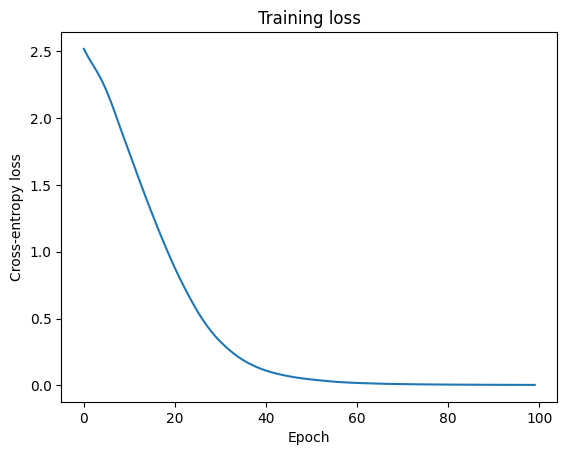

In [5]:
torch.manual_seed(42)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
losses = []
model.train()
for epoch in range(100):
    optimizer.zero_grad()  # clear previous gradients
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 20 == 0:
        accuracy = (logits.argmax(1) == y).float().mean().item()
        print(f'Epoch {epoch+1:3d}/100 | Loss: {loss.item():.4f} | Train accuracy: {accuracy:.1%}')
model.eval()
with torch.no_grad():
    final_logits, _ = model(X)
    final_acc = (final_logits.argmax(1) == y).float().mean().item()
print(f'Training finished! Final training accuracy: {final_acc:.1%}')
plt.plot(losses)
plt.xlabel('Epoch'); plt.ylabel('Cross-entropy loss'); plt.title('Training loss'); plt.show()

## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

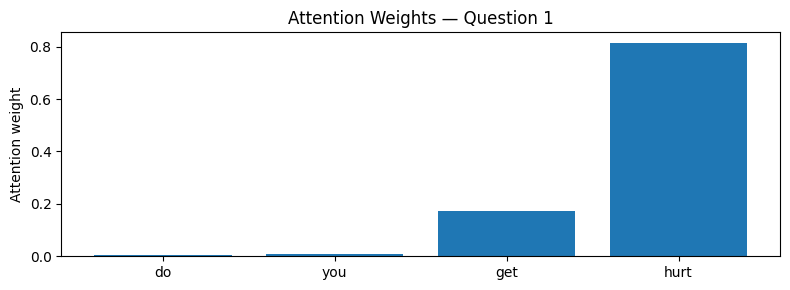

Question: do you get hurt?
Highest attention word: hurt


In [6]:
question = df.loc[0, 'question']
words = tokenize(question)
with torch.no_grad():
    prediction, weights = model(X[0:1])
plt.figure(figsize=(8, 3))
plt.bar(range(len(words)), weights[0, :len(words)].tolist())
plt.xticks(range(len(words)), words)
plt.title('Attention Weights — Question 1')
plt.ylabel('Attention weight')
plt.tight_layout(); plt.show()
print('Question:', question)
print('Highest attention word:', words[weights[0, :len(words)].argmax().item()])

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

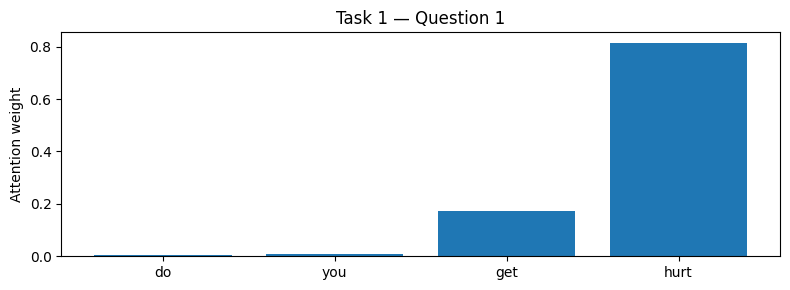

Question: do you get hurt?
Highest attention word: hurt
Highest attention weight: 0.8138
Predicted answer: I don't have a body.
-----------------------------------------------------------------


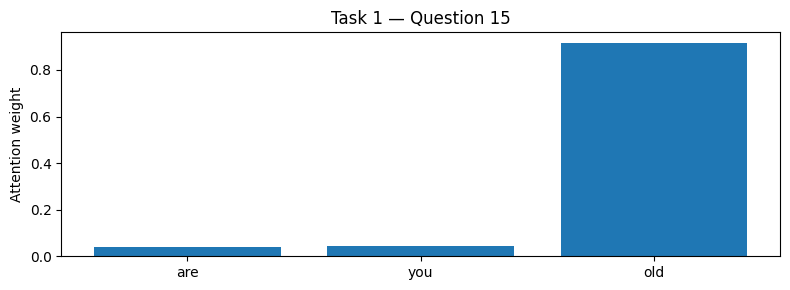

Question: are you old?
Highest attention word: old
Highest attention weight: 0.9157
Predicted answer: Age doesn't really apply to me.
-----------------------------------------------------------------


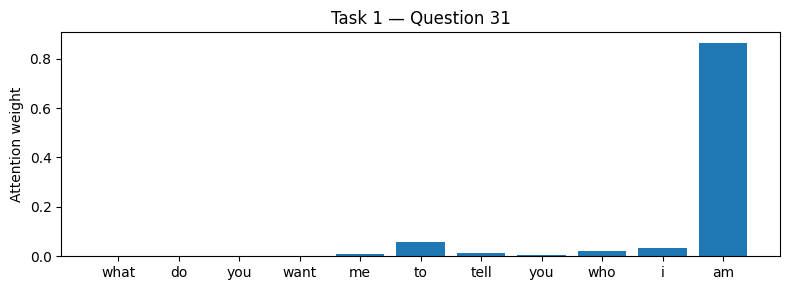

Question: what do you want me to tell you who i am?
Highest attention word: am
Highest attention weight: 0.8631
Predicted answer: I'm better at answering questions.
-----------------------------------------------------------------
TASK 1 — OBSERVATIONS
Question 1: The highest-attention word is "hurt". It may carry information specific to the question.
Question 15: The highest-attention word is "old". It may carry information specific to the question.
Question 31: The highest-attention word is "am". It may carry information specific to the question.
Conclusion: Attention weights indicate which token positions the trained model emphasized. High attention may highlight important words, but it does not prove that a word is the sole reason for a prediction.


In [7]:
# Task 1: Three different questions from different answer groups.
selected_indices = [0, 14, 30]
assert max(selected_indices) < len(df)

# Helper: get weights, predicted answer and top-attended word.
def inspect_question(index):
    words = tokenize(df.loc[index, 'question'])
    with torch.no_grad():
        logits, attention = model(X[index:index+1])
    scores = attention[0, :len(words)].cpu().numpy()
    top_index = int(scores.argmax())
    predicted_id = classes[int(logits.argmax(dim=1).item())]
    return words, scores, words[top_index], predicted_id

for idx in selected_indices:
    words, scores, top_word, predicted_id = inspect_question(idx)
    plt.figure(figsize=(8, 3))
    plt.bar(range(len(words)), scores)
    plt.xticks(range(len(words)), words)
    plt.title(f'Task 1 — Question {idx+1}')
    plt.ylabel('Attention weight')
    plt.tight_layout(); plt.show()
    print('Question:', df.loc[idx, 'question'])
    print('Highest attention word:', top_word)
    print('Highest attention weight:', round(float(max(scores)), 4))
    print('Predicted answer:', answer_lookup[predicted_id])
    print('-'*65)

# Answer to Task 1: print a conclusion based on the actual model output.
print('TASK 1 — OBSERVATIONS')
for idx in selected_indices:
    words, scores, top_word, _ = inspect_question(idx)
    informative = top_word not in {'do','you','are','can','the','a','an','is','what','how','have','i','we'}
    print(f'Question {idx+1}: The highest-attention word is "{top_word}". '
          + ('It may carry information specific to the question.' if informative else
             'It is a common word, so the highest attention is not necessarily the most meaningful word.'))
print('Conclusion: Attention weights indicate which token positions the trained model emphasized. '
      'High attention may highlight important words, but it does not prove that a word is the sole reason for a prediction.')

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

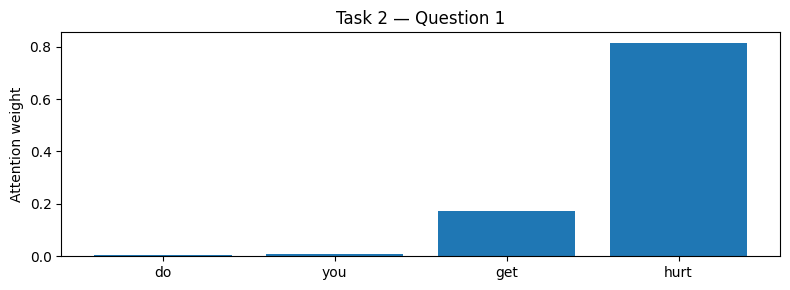

Question: do you get hurt?
Highest attention word: hurt
Predicted answer: I don't have a body.
-----------------------------------------------------------------


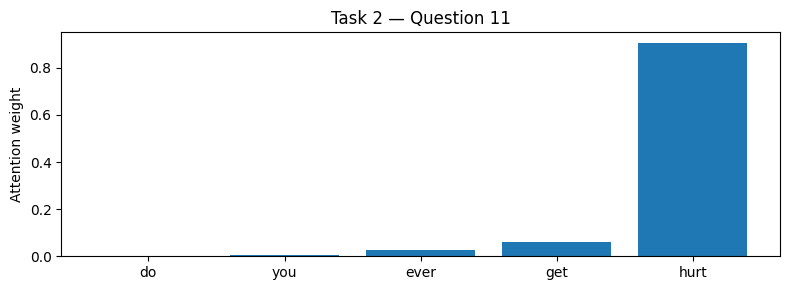

Question: do you ever get hurt?
Highest attention word: hurt
Predicted answer: I don't have a body.
-----------------------------------------------------------------
TASK 2 — COMPARISON AND ANSWER
The highest-attention words are "hurt" and "hurt".
The model emphasizes the same word in both questions, suggesting that this shared token is useful for its learned representation.
Conclusion: Attention assigns context-dependent weights to words. Similar questions can produce similar or different attention patterns; attention weights alone do not establish semantic understanding.


In [8]:
# Task 2: Two differently worded questions with the same answer_id.
# Dataset rows 0 and 10 ask about getting hurt, but use different wording.
similar_indices = [0, 10]
assert df.loc[similar_indices[0], 'answer_id'] == df.loc[similar_indices[1], 'answer_id']

for idx in similar_indices:
    words, scores, top_word, predicted_id = inspect_question(idx)
    plt.figure(figsize=(8, 3))
    plt.bar(range(len(words)), scores)
    plt.xticks(range(len(words)), words)
    plt.title(f'Task 2 — Question {idx+1}')
    plt.ylabel('Attention weight')
    plt.tight_layout(); plt.show()
    print('Question:', df.loc[idx, 'question'])
    print('Highest attention word:', top_word)
    print('Predicted answer:', answer_lookup[predicted_id])
    print('-'*65)

a = inspect_question(similar_indices[0])[2]
b = inspect_question(similar_indices[1])[2]
print('TASK 2 — COMPARISON AND ANSWER')
print(f'The highest-attention words are "{a}" and "{b}".')
if a == b:
    print('The model emphasizes the same word in both questions, suggesting that this shared token is useful for its learned representation.')
else:
    print('The model emphasizes different words despite the similar meanings. Attention can change with word order and surrounding context.')
print('Conclusion: Attention assigns context-dependent weights to words. Similar questions can produce similar or different attention patterns; attention weights alone do not establish semantic understanding.')